# Lineære ligningssystemer
I denne session vil vi fokusere på forståelse af lineære funktioner. Specifikt vil vi undersøge rammerne for **lineær algebra**, som giver en måde at repræsentere og forstå løsningerne på **systemer med lineære ligninger**. Et system med lineære ligninger består af flere relaterede *funktioner* med et fælles sæt *variabler*. Mange processer fra den virkelige verden kan modelleres ved hjælp af flere relaterede lineære ligninger. Vi begynder med at udforske et konkret eksempel på et lineært system, et andet ord for system med lineære ligninger, inden vi dykker længere ned i lineær algebra.


> ### Dagens lektion
> * **Emne**: Lineære ligningssystemer - her starter kursets anden halvdel om lineær algebra.
> * **Matematik (opfriskning)**: ligningssystemer, totalmatricen (augmented matrix), rækkeoperationer, Gauss-elimination.
> * **Python i dag**: numpy-arrays og indeksering, `np.array` (2D), `sympy.linsolve`, `np.linalg.solve`.
> * **Husk**: Kør cellerne oppefra og ned. Opfører noget sig mærkeligt: *Runtime → Restart session and run all*.


#### Tutoring vs. Part-time job

Forestil dig, at du har to jobmuligheder mens du studerer. Du kan enten blive tutor eller tage et deltidsjob.

Hvis du vælger at blive tutor, har du en ugentlig basisløn på 1000 kr og du får 150 kr i timen for hver time du underviser. Vi kan repræsentere dette som $y = 1000 + 150x$, hvor $y$ repræsenterer kroner tjent om ugen og $x$ repræsenterer undervisningstimer om ugen.

Hvis du vælger et deltidsjob, har du en ugentlig basisløn på 500 kr og du får 200 kr i timen. Dette kan repræsenteres som $y = 500 + 200x$, hvor $y$ også repræsenterer kr tjent om ugen og $x$ repræsenterer arbejdstimer om ugen.

Vi ønsker at forstå, hvilket jobtilbud der er bedre. Hvis vi ved nøjagtigt det beløb, vi gerne vil tjene hver uge ($y$), kan vi erstatte denne værdi i begge ligninger og løse for at identificere, hvilket job der kræver, at vi arbejder færre timer. Hvis vi ved nøjagtigt det antal timer, vi vil arbejde hver uge ($x$), kan vi erstatte denne værdi i begge ligninger og løse for at identificere, hvilket job der giver os flere penge for den samme mængde arbejdede timer.

**Vi ønsker i stedet at finde ud af:**
* Ved hvilket antal arbejdstimer kan vi forvente at tjene det samme beløb på begge job?
* Hvor mange timer skal vi arbejde for at tjene flere penge ved deltidsjob end som tutor?

For at besvare det første spørgsmål skal vi finde værdien, hvor begge værdier er ækvivalente. Når vi først ved, hvor de krydser hinanden, kan vi let finde ud af svar på det andet spørgsmål.

Lad os starte med at visualisere begge disse ligninger på et plot og få en visuel forståelse for, hvor de krydser hinanden.

* Brug numpy.linspace() til at generere 1000 jævnt fordelte værdier mellem 0 og 50 og tildel til $x$.
* Transformér $x$ ved hjælp af ligningen $y = 1000 + 150x$, og tildel resultatet til y1.  
* Transformér $x$ ved hjælp af ligningen $y = 500 + 200x$, og tildel resultatet til y2.
* Generer 2 linjediagrammer på samme delplot:
  - En med $x$ på x-aksen og y1 på y-aksen. Indstil linjefarven til "gold".
  - En med $x$ på x-aksen og y2 på y-aksen. Indstil linjefarven til "blue".

Undgå at vælge et værdiinterval for x- og y-akserne, og lad i stedet matplotlib vælge automatisk baseret på data.

In [1]:
# Importer NumPy som np og Matplotlib.pyplot som plt
import numpy as np
np.set_printoptions(suppress=True)
import matplotlib.pyplot as plt

In [2]:
x = np.linspace(0, 50, num=1000)

In [3]:
x

array([ 0.        ,  0.05005005,  0.1001001 ,  0.15015015,  0.2002002 ,
        0.25025025,  0.3003003 ,  0.35035035,  0.4004004 ,  0.45045045,
        0.5005005 ,  0.55055055,  0.6006006 ,  0.65065065,  0.7007007 ,
        0.75075075,  0.8008008 ,  0.85085085,  0.9009009 ,  0.95095095,
        1.001001  ,  1.05105105,  1.1011011 ,  1.15115115,  1.2012012 ,
        1.25125125,  1.3013013 ,  1.35135135,  1.4014014 ,  1.45145145,
        1.5015015 ,  1.55155155,  1.6016016 ,  1.65165165,  1.7017017 ,
        1.75175175,  1.8018018 ,  1.85185185,  1.9019019 ,  1.95195195,
        2.002002  ,  2.05205205,  2.1021021 ,  2.15215215,  2.2022022 ,
        2.25225225,  2.3023023 ,  2.35235235,  2.4024024 ,  2.45245245,
        2.5025025 ,  2.55255255,  2.6026026 ,  2.65265265,  2.7027027 ,
        2.75275275,  2.8028028 ,  2.85285285,  2.9029029 ,  2.95295295,
        3.003003  ,  3.05305305,  3.1031031 ,  3.15315315,  3.2032032 ,
        3.25325325,  3.3033033 ,  3.35335335,  3.4034034 ,  3.45

In [4]:
len(x)

1000

In [5]:
y1 = 1000 + 150*x

In [6]:
y2 = 500 + 200*x

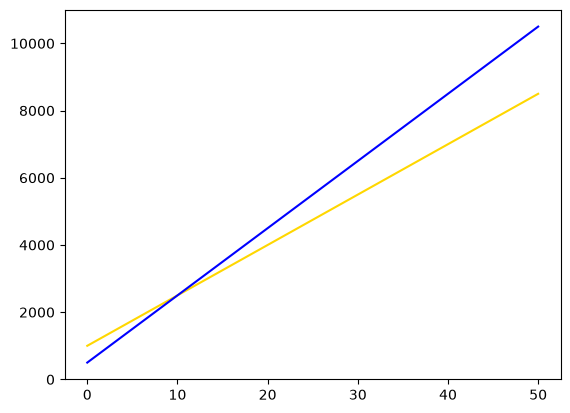

In [7]:
plt.plot(x, y1, color = "gold")
plt.plot(x, y2, color = 'blue')

## Løsning af lineært system
Fra plottet vi har genereret, kan vi fortælle, at begge funktioner skærer hinanden et sted nær $x = 10$

Dette punkt, hvor begge ligninger krydser, er kendt som en **løsning** på systemet, fordi at erstatte $x$ og $y$ i begge funktioner i systemet gør dem begge sande. Sagt på en anden måde, ved at tilslutte $x$ værdien af løsningen til begge funktioner giver den samme $y$ værdi.

Lad os undersøge, hvordan man løser dette system manuelt. Fordi begge funktioner deler de samme variabler, kan vi repræsentere en af variablerne, for eksempel $y$ med hensyn til den anden variabel og løse $x$ værdien. Derefter kan vi erstatte denne $x$ værdi i begge ligninger for at bestemme $y$ værdien. Denne proces er kendt som **løsning ved eliminering** eller **eliminationsmetoden**. Lad os gennemgå, hvordan vi anvender denne proces på vores system.

Først erstatter vi $y$ i den anden funktion med den første funktion:


\begin{equation}
\begin{split}
y & = {1000 + 150x} \\
y & = {500 + 200x}
\end{split}
\rightarrow 1000 - 500 = 200x - 150x \rightarrow 500 = 50x \rightarrow 10 = x
\end{equation}

Bemærk, at rækkefølge ikke er vigtig, og vi kunne også have erstattet $y$ i den første funktion med den anden funktion. Nu hvor vi ved at $x = 10$, kan vi erstatte dette i begge ligninger for at bestemme $y$.

\begin{equation}
\begin{split}
y & = {1000 + 150(10)} \\
y & = {500 + 200(10)}
\end{split}
\rightarrow
\begin{split}
y & = 2500 \\
y & = 2500
\end{split}
\end{equation}

Løsningen på vores system er (10, 2500). Dette betyder, at hvis vi arbejder nøjagtigt 10 timer om ugen, tjener vi det samme beløb på begge job: 2500.

Mens vi kan løse et lineært system som dette manuelt ved hjælp af aritmetik, kan vi ikke bruge den samme teknik til at løse meget mere komplekse systemer. Mange processer i den virkelige verden er modelleret ved hjælp af langt flere end 2 variabler og funktioner, og det er umuligt at løse manuelt. Disse typer systemer kan løses ved hjælp af lineær algebra ved hjælp af en variation af aritmetisk eliminering kaldet **Gaussisk-eliminering**. Vi gennemgår, hvordan man udfører Gauss-elimination i det følgende for at finde en løsning på vores lineære system.

## Matrix eliminering
Lineær algebra giver en måde at repræsentere et lineært system på kompakt måde, kendt som en **matrix**, og et sæt regler til manipulation af denne repræsentation, også kendt som en **algebra**. En matrix bruger rækker og kolonner til kun at repræsentere koefficienterne i et lineært system, og det svarer til den måde, data er repræsenteret i et regneark eller en dataramme. Før vi kan repræsentere vores system i en matrix, er vi nødt til at om-arrangere hver af vores funktioner i den **generelle form**.


Fra kursets første halvdel (og gymnasiet) ved I, at lineære funktioner ofte skrives i hældningsafskæringsform (slope-intercept form):
> $y = ax + b$

I lineær algebra repræsenterer vi normalt lineære funktioner i den generelle form:
> $Ax + By = c$

I den generelle form er variablerne og deres koefficienter på *venstre* side, mens det konstante term er på *højre* side. Vi kan skifte fra hældningsafskæringsform til den generelle form ved at om-arrangere:
> $ax − y = −b$

Sådan ser den første funktion ud i generel form:
> $150x − y = -1000$

Sådan ser den anden funktion ud i generel form:
> $200x − y = -500$




For at repræsentere begge lineære funktioner i et system bruger vi en **augmenteret matrix**:



$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$


I en augmenteret matrix er koefficienterne fra venstre side af funktionerne på venstre side af bjælken (|), mens konstanterne fra højre side af funktionerne er på højre side. En augmenteret matrix giver os mulighed for at repræsentere et lineært system, der kun bruger det reelle antal koefficienter og konstanter.

Her er et resumé af de 3 forskellige repræsentationer af det lineære system, vi lige har diskuteret:

**slope-intercept form**
$$
y  = 1000 + 150x \\
y  = 500 + 200x
$$

**general form**

 $$150x − y = -1000\\
 200x − y = -500 $$

**augmented matrix**

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

I den næste del gennemgår vi, hvordan vi repræsenterer denne augmenterede matrix i **NumPy**. I senere sessioner lærer vi reglerne for matrixmanipulation og hvordan vi anvender dem for at nå frem til systemets løsning.

### Matricer i Python
I kender numpy-arrays som rækker af tal - nu tilføjer vi en dimension: rækker *og* kolonner. For at repræsentere en augmenteret matrix kan vi bruge `numpy.array()` funktionen og videregive hver række som en liste fra den øverste række til den nederste række. Den følgende kode repræsenterer en matrix med 2 rækker og 3 kolonner, der udelukkende indeholder 0'er:


In [8]:
random_matrix_med_mange_0 = np.array([
                         [0, 0, 0],
                         [0, 0, 0]
])

In [9]:
dom_matrix_med_mange_0

NameError: name 'dom_matrix_med_mange_0' is not defined

En numpy-matrix (array) har en shape, og der er flere indbyggede funktioner som man kan bruge til at manipulere en matrix.

In [10]:
random_matrix_med_mange_0.shape

(2, 3)

lad os bruge vores værdier fra casen

her kan vi se, at der er 2 rækker og 3 kolonner
Opret nu en NumPy 2d-**array** af vores augmenterede case-matrix "`matrix_one`"

In [11]:
# Løsning af lineært system i generel form
matrix_one = np.array([
                         [150, -1, -1000],
                         [200, -1, -500]
], dtype=np.float32)
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

`np.array` eller `np.asarray` kan også bruges til at danne en matrix med udganspunkt i en `pandas` dataframe.
Pandas dataframes selv har også en funktion, som hedder `to_numpy` - hvilket vil gøre det samme.
Dvs. det er rigtig nemt at gå fra tabular data til matrix og omvendt, hvor man kan bruge `pd.DataFrame` til at lave en matrix om til en dataframe.





In [12]:
import pandas as pd

In [13]:
df = pd.DataFrame([[150, -1, -1000],
                   [200, -1, -500]], columns=['v1','v2','v3'])
df

,v1,v2,v3
0,150,-1,-1000
1,200,-1,-500


In [14]:
df.to_numpy()

array([[  150,    -1, -1000],
       [  200,    -1,  -500]])

I dette kursus kommer vi som udgangspunkt ikke til at arbejde med pandas og dataframes, men ligesom med numpy er det grundlæggende redskaber til at lave data-videnskab i Python, og vil blive introduceret og bearbejdet i senere kurser.  

### Matrix løsning i Python
Det vigtige spørgsmål er nu, hvordan når vi frem til den samme løsning, som vi gjorde tidligere med aritmetik? Tidligere brugte vi aritmetik til at beregne løsningen på systemet og repræsenterede det som et koordinatpar: (10, 2500).

Når vi arbejder med matrixrepræsentationen, kan løsningen skrives som:

$$
\left[\begin{array}{rr|r}
1 & 0 & 10 \\
0 & 1 & 2500
\end{array}\right]
$$


Intuition kan ses her:


**Hvis dette**

$$
\begin{align}
150x − y = -1000\\
200x − y = -500 \\
\end{align}
$$

**kan oversættes til det her**

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

**så kan man vel skrive**

$$
\left[\begin{array}{rr|r}
1 & 0 & 10 \\
0 & 1 & 2500
\end{array}\right]
$$

**som**

$$
\begin{align}
1x + 0y = 10\\
0x + 1y = 2500 \\
\end{align}
$$




For at løse et lineært system er vi nødt til at udføre en række transformationer for at forsøge at udvikle matrixen til denne form (hvor løsningen præsenteres). Ikke alle lineære systemer har dog løsninger, og vi vil undersøge dette nærmere i løbet af dette kursus.

#### Rækkeoperationer

For at bevare forholdene i det lineære system kan vi kun bruge følgende rækkeoperationer:

1. rækker kan ombyttes

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow \text{Byt } R_1\  \& \  R_2$$

$$
\left[\begin{array}{rr|r}
200 & -1 & -500\\
150 & -1 & -1000
\end{array}\right]
$$

2. Enhver række kan multipliceres med en konstant der ikke er 0:

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow 2·R_1\  3·R_2 $$

$$
\left[\begin{array}{rr|r}
300 & -2 & -2000\\
600 & -3 & -1500
\end{array}\right]
$$

3. Enhver række kan tilføjes en anden række

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow R_2 = R_1 + R_2 $$

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000\\
350 & -2 & -1500
\end{array}\right]
$$

Selvom disse kan virke nye, er rækkeoperationerne de samme tilladte operationer, som vi kan udføre, når funktionerne er i ligningsform. Før vi dykker ned i, hvordan vi løser vores lineære system ved hjælp af disse rækkeoperationer, kan vi først øve os på at udføre disse transformationer i NumPy.

For at bytte 2 rækker i et NumPy ndarray-objekt skal vi bruge dobbelt parentesnotation til at angive ændringen i rækkefølgen:


In [15]:
matrix = np.array([
                     [20, 4],
                     [66, 7]
])

In [16]:
matrix

array([[20,  4],
       [66,  7]])

In [17]:
#vis R1
matrix[0,:]

array([20,  4])

In [18]:
# Vis R2
matrix[1,:]

array([66,  7])

In [19]:
# Vis K1
matrix[:,0]

array([20, 66])

In [20]:
# Vis det hele
matrix

array([[20,  4],
       [66,  7]])

In [21]:
# Byt R1 & R2
matrix_swap = matrix[[1,0],:]

In [22]:
matrix_swap

array([[66,  7],
       [20,  4]])

For at multiplicere en række med en ikke-nul konstant vælger vi rækken, bruger * operatoren til at multiplicere alle værdierne med en skalær værdi og tildeler derefter den transformerede række tilbage:

In [23]:
# Multiplicer anden række med 2:
matrix[1] = 2*matrix[1]

For at tilføje en række til en anden række skal vi tilføje begge rækker og derefter tildele den tilbage til den række, vi vil overskrive:

In [24]:
# Tilføj den første række til den anden:
matrix[1] = matrix[1] + matrix[0]

Bemærk, at du ikke kan gange eller dele med andre rækker.


#### Echelonform
For at finde løsningerne i en matrix er der to hovedtrin, vi skal tage. Det første trin er at om-arrangere matrixen i **echelon-form**. I denne form er værdierne på de diagonale placeringer alle lig med 1, og værdierne under diagonalen er alle lig med 0.

$$
\left[\begin{array}{rr|r}
1 & ? & ? \\
0 & 1 & ?
\end{array}\right]
$$

In [25]:
matrix_one = np.array([
                         [150, -1, -1000],
                         [200, -1, -500]
], dtype=np.float32)
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

Vi kan først dele den første række med 150, så den diagonale værdi på den første række bliver 1

$$R_1 = R_1 / 150$$

In [26]:
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

In [27]:
matrix_one[0] = matrix_one[0]/150

In [28]:
matrix_one

array([[   1.        ,   -0.00666667,   -6.6666665 ],
       [ 200.        ,   -1.        , -500.        ]], dtype=float32)

Lad os derefter trække 200 gange den første række fra anden række:

In [29]:
matrix_one[1] = matrix_one[1] - 200*matrix_one[0]

In [30]:
matrix_one

array([[  1.        ,  -0.00666667,  -6.6666665 ],
       [  0.        ,   0.33333337, 833.33325   ]], dtype=float32)

Lad os udføre de sidste transformationer for at få matrixen helt til reduceret echelon-form, hvor løsningen kan aflæses direkte

In [31]:
matrix_one[1] = matrix_one[1] * (1/matrix_one[1,1])

In [32]:
matrix_one

array([[   1.        ,   -0.00666667,   -6.6666665 ],
       [   0.        ,    1.        , 2499.9995    ]], dtype=float32)

In [33]:
matrix_one[0] = matrix_one[0] - (matrix_one[1] * matrix_one[0,1])

In [34]:
matrix_one

array([[   1.      ,    0.      ,    9.999998],
       [   0.      ,    1.      , 2499.9995  ]], dtype=float32)

$$\left[\begin{array}{rr|r}
1 & 0 & ? \\
0 & 1 & ?
\end{array}\right]$$

Nu kan vi sige, at $x = 10$ og $y =2500$

In [35]:
# vi kan bruge SymPy til at tjekke vores beregninger

from sympy import symbols, linsolve, Matrix # importer det, vi bruger, fra SymPy
from sympy.solvers.solveset import linsolve #importer linalg solver

x, y = symbols('x, y') #definer vores symboler

linsolve(Matrix(([150,    -1, -1000], [200, -1, -500])), (x, y)) #definer matrix og hvad der skal løses

{(10, 2500)}

### Flere uafhængige variable
I de fleste situationer i den virkelige verden er den afhængige variabel forbundet med flere uafhængige variabler, ikke kun et enkelt x. For at repræsentere disse funktioner skal vi arbejde med en anden version af den generelle form:

$a_1x_1 + a_2x_2 + a_3x_3 + … + a_nx_n = c$


I denne form er $a_1…a_n$ koefficienterne og $c$ er en konstant værdi.

$$
\begin{align*}2x_1 + 5x_2 + 2x_3 &=  - 38\\  3x_1 - 2x_2 + 4x_3 &= 17\\   - 6x_1 + x_2 - 7x_3 &=  - 12\end{align*}
$$


$$\left[\begin{array}{rrr|r}
2 & 5 & 2 & -38\\
3 & -2 & 4 & 17\\
-6 & 1 & -7 & -12
\end{array}\right]$$


In [36]:
matrix_3x4 = np.array([[2,5,2,-38],
                         [3,-2,4,17],
                         [-6,1,-7,-12]] , dtype = np.float32)

In [37]:
x1, x2, x3 = symbols('x1, x2, x3') # som her kan være alt man har lyst til...men lad os bruge x1...n

linsolve(Matrix(matrix_3x4), (x1, x2, x3))

{(3.0, -8.0, -2.0)}

Hvis vi har et system med mere end 3 variabler, kan vi ikke visualisere det let. Derudover bliver det meget mere problematisk at udføre Gaussisk-eliminering. I de næste par sessioner vil vi udvikle mere af teorien og den geometriske intuition bag lineær algebra og bygge videre på det for at løse disse mere komplekse lineære systemer.

# **Begreber**

* Lineær algebra giver en måde at repræsentere og forstå løsninger på systemer med lineære ligninger. Vi repræsenterer lineære ligninger i den generelle form $Ax + By = c$.

* Et system med lineære ligninger består af flere relaterede funktioner med et fælles sæt variabler. Det punkt, hvor ligningerne krydser hinanden, er kendt som en løsning på systemet.

* Elimineringsmetoden indebærer at repræsentere en af vores variabler med hensyn til en ønsket variabel og erstatte ligningen, der er i form af den ønskede variabel.

  * Antag, at vi har ligningerne $y = 1000 + 30x$ og $y = 100 + 50x$. Da begge er lig med y, kan man bytte den anden funktion med den første. Følgende er trinene til løsning af vores eksempel ved hjælp af eliminationsmetoden:
    * $1000 + 30x = 100 + 50x$
    * $900 = 20x$
    * $45 = x$

* En matrix bruger rækker og kolonner til udelukkende at repræsentere koefficienterne i et lineært system, og det svarer til den måde, hvorpå data er repræsenteret i et regneark eller en DataFrame.

* Gaussisk eliminering bruges til at løse ligningssystemer, der er modelleret af mange variabler og ligninger.

* I en augmenteret matrix er koefficienterne fra funktionens venstre side på venstre side af bjælken (|), mens konstanterne fra funktionens højre side er på højre side.

* For at bevare forholdene i det lineære system kan vi bruge følgende rækkeoperationer:
  * Enhver række kan byttes med en anden.
  * Enhver række kan ganges med en ikke-nul konstant.
  * Enhver række kan føjes til en anden række.
